# LeNet 图像分类：从零到完整训练

本 Notebook 使用 **MNIST 手写数字数据集**，带注释地实现 LeNet 网络的完整训练流程。

内容结构：
1. 环境准备（导入库、固定随机种子）
2. 数据集（Dataset）
3. 数据预处理（Transforms）
4. 数据加载器（DataLoader）
5. 网络定义
6. 损失函数与优化器
7. 训练与评估
8. 可视化结果

In [1]:
## ── 1. 导入库 & 固定随机种子 ──────────────────────────
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 固定随机种子，保证每次运行结果一致
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 优先使用 GPU，否则用 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

使用设备: cpu


## 2. 数据集（Dataset）

`torchvision.datasets.MNIST` 封装了 MNIST 数据集，使用时只需指定：
- `root`：数据存放路径
- `train=True/False`：训练集还是测试集
- `download=True`：若本地不存在则自动下载
- `transform`：对每张图片应用的预处理流水线（见下一节）

每次通过 `dataset[i]` 取数据时，`transform` 会自动作用在图片上。

## 3. 数据预处理（Transforms）

`transforms.Compose` 将多个预处理步骤串联成一条流水线，按顺序依次执行：

| 步骤 | 作用 |
|------|------|
| `ToTensor()` | PIL Image → `torch.Tensor`，像素值从 [0,255] 缩放到 [0.0, 1.0] |
| `Normalize(mean, std)` | 标准化：每个像素 `(x - mean) / std`，将分布中心化到 0 附近 |

MNIST 是灰度图（1 通道），所以 `mean=(0.5,)` 和 `std=(0.5,)` 将像素从 [0,1] 线性映射到 [-1,1]。

训练集大小: 60000
测试集大小: 10000
图片张量形状: torch.Size([1, 28, 28])
标签: 5


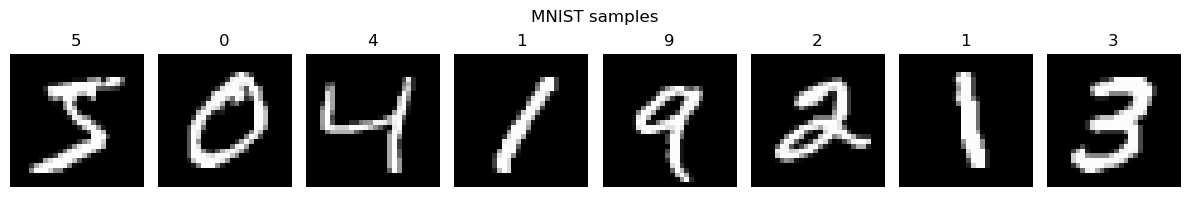

In [2]:
## ── 2 & 3. 加载数据集，同时定义预处理流水线 ──────────────
transform = transforms.Compose([
    transforms.ToTensor(),                        # PIL → Tensor，像素归一化到 [0,1]
    transforms.Normalize(mean=(0.5,), std=(0.5,)) # 再映射到 [-1,1]
])

train_set = datasets.MNIST(root="../../data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root="../../data", train=False, download=True, transform=transform)

print(f"训练集大小: {len(train_set)}")
print(f"测试集大小: {len(test_set)}")

# 查看单张样本
img, label = train_set[0]
print(f"图片张量形状: {img.shape}")   # [1, 28, 28]：通道 x 高 x 宽
print(f"标签: {label}")               # 0~9 的整数

# 可视化前 8 张样本
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img_i, lbl_i = train_set[i]
    # img_i 形状 [1,28,28]，squeeze 去掉通道维
    ax.imshow(img_i.squeeze(), cmap="gray")
    ax.set_title(str(lbl_i))
    ax.axis("off")
plt.suptitle("MNIST samples")
plt.tight_layout()
plt.show()

## 4. 数据加载器（DataLoader）

`DataLoader` 负责将 Dataset 中的样本**打包成 mini-batch** 供训练使用。

关键参数：
- `batch_size`：每个 batch 包含多少张图片
- `shuffle=True`：训练时每个 epoch 随机打乱顺序，防止模型记住样本顺序
- `num_workers`：用多少个子进程并行预读数据（0 表示主进程读）

每次 `for images, labels in loader` 迭代，就会取出一个形状为 `[batch_size, 1, 28, 28]` 的 Tensor。

In [3]:
## ── 4. 创建 DataLoader ──────────────────────────────────
BATCH_SIZE = 128

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# 查看一个 batch 的形状
images, labels = next(iter(train_loader))
print(f"一个 batch 的图片形状: {images.shape}")  # [128, 1, 28, 28]
print(f"一个 batch 的标签形状: {labels.shape}")  # [128]

一个 batch 的图片形状: torch.Size([128, 1, 28, 28])
一个 batch 的标签形状: torch.Size([128])


## 5. 网络定义

LeNet 由两个卷积块和两个全连接层组成：

```
输入 [B, 1, 28, 28]
  → Conv(1→20, K=5, P=2) → ReLU → MaxPool(2×2)   → [B, 20, 14, 14]
  → Conv(20→50, K=5, P=2) → ReLU → MaxPool(2×2)  → [B, 50,  7,  7]
  → Flatten                                        → [B, 2450]
  → Linear(2450→500) → ReLU                        → [B, 500]
  → Linear(500→10)                                 → [B, 10]
```

**`nn.Module`** 是所有网络层的基类，自定义网络需要：
1. 在 `__init__` 中定义所有层
2. 在 `forward` 中描述数据流动的方式

In [4]:
## ── 5. 定义 LeNet 网络 ──────────────────────────────────
class LeNet5(nn.Module):
    """
    输入: [B, 1, 28, 28]
    输出: [B, 10]
    """

    def __init__(self):
        super().__init__()
        # 卷积层：in_channels, out_channels, kernel_size, padding
        self.conv1 = nn.Conv2d(1, 20, kernel_size=5, padding=2)   # → [B, 20, 28, 28]
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)         # → [B, 20, 14, 14]
        self.conv2 = nn.Conv2d(20, 50, kernel_size=5, padding=2)  # → [B, 50, 14, 14]
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)         # → [B, 50,  7,  7]
        # 全连接层：50 × 7 × 7 = 2450 个输入特征
        self.fc1   = nn.Linear(50 * 7 * 7, 500)                   # → [B, 500]
        self.fc2   = nn.Linear(500, 10)                            # → [B,  10]

    def forward(self, x):
        x = self.pool1(torch.relu(self.conv1(x)))  # 卷积 → 激活 → 池化
        x = self.pool2(torch.relu(self.conv2(x)))  # 卷积 → 激活 → 池化
        x = x.view(x.size(0), -1)                  # 展平为一维向量
        x = torch.relu(self.fc1(x))                # 全连接 + 激活
        x = self.fc2(x)                            # 全连接（输出 logit）
        return x

model = LeNet5().to(device)
print(model)

# 统计总参数量
total = sum(p.numel() for p in model.parameters())
print(f"\n总参数量: {total:,}")

LeNet5(
  (conv1): Conv2d(1, 20, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(20, 50, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2450, out_features=500, bias=True)
  (fc2): Linear(in_features=500, out_features=10, bias=True)
)

总参数量: 1,256,080


## 6. 损失函数与优化器

**损失函数** `CrossEntropyLoss`：
- 适用于多分类问题，内部已包含 Softmax，所以网络最后一层不需要再加 Softmax
- 输入：网络输出的 logit `[B, 10]` 和真实标签 `[B]`

**优化器** `SGD`：
- 随机梯度下降，`momentum=0.9` 加入动量，加速收敛并减少震荡
- `lr` 是学习率，控制每次参数更新的步长大小

**学习率调度器** `StepLR`：
- 每隔 `step_size` 个 epoch 将学习率乘以 `gamma`，防止后期学习率过大导致震荡

In [5]:
## ── 6. 损失函数、优化器、学习率调度器 ──────────────────
LR     = 0.01
EPOCHS = 10

# 交叉熵损失（内部已包含 Softmax，网络末层直接输出 logit 即可）
criterion = nn.CrossEntropyLoss()

# SGD + 动量
optimizer = optim.SGD(model.parameters(), lr=LR, momentum=0.9)

# 每 5 个 epoch 学习率 × 0.5
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

print("损失函数:", criterion)
print("优化器:  ", optimizer)

损失函数: CrossEntropyLoss()
优化器:   SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    initial_lr: 0.01
    lr: 0.01
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0
)


## 7. 训练与评估

每个 epoch 的训练步骤：
1. `model.train()` — 切换到训练模式
2. 遍历 `train_loader`，取出一个 batch
3. `optimizer.zero_grad()` — 清空上一步累积的梯度
4. `model(images)` — 前向传播，得到预测 logit
5. `criterion(...)` — 计算损失
6. `loss.backward()` — 反向传播，计算梯度
7. `optimizer.step()` — 用梯度更新参数

评估时用 `torch.no_grad()` 禁用梯度计算，节省内存，并调用 `model.eval()` 关闭 Dropout/BatchNorm 的训练行为。

In [6]:
## ── 7. 训练与评估函数 ───────────────────────────────────
def train_one_epoch(model, loader, criterion, optimizer, device):
    """跑一轮训练，返回平均损失和准确率。"""
    model.train()                                      # 训练模式
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                          # 清空梯度
        outputs = model(images)                        # 前向传播
        loss = criterion(outputs, labels)              # 计算损失
        loss.backward()                                # 反向传播
        optimizer.step()                               # 更新参数

        total_loss += loss.item() * images.size(0)
        correct    += (outputs.argmax(dim=1) == labels).sum().item()
        total      += images.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """在测试集上评估模型，返回平均损失和准确率。"""
    model.eval()                                       # 评估模式
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss    = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        correct    += (outputs.argmax(dim=1) == labels).sum().item()
        total      += images.size(0)

    return total_loss / total, correct / total

In [7]:
## ── 8. 训练循环 ─────────────────────────────────────────
train_losses, test_losses = [], []
train_accs,   test_accs   = [], []

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    te_loss, te_acc = evaluate(model, test_loader, criterion, device)

    train_losses.append(tr_loss);  test_losses.append(te_loss)
    train_accs.append(tr_acc);     test_accs.append(te_acc)

    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch [{epoch:2d}/{EPOCHS}]  lr={lr_now:.5f}  "
          f"Train Loss={tr_loss:.4f}  Train Acc={tr_acc*100:.2f}%  |  "
          f"Test  Loss={te_loss:.4f}  Test  Acc={te_acc*100:.2f}%")

    scheduler.step()   # 按计划衰减学习率

print(f"\n最终测试准确率: {test_accs[-1]*100:.2f}%")

Epoch [ 1/10]  lr=0.01000  Train Loss=0.3233  Train Acc=90.22%  |  Test  Loss=0.0650  Test  Acc=97.99%
Epoch [ 2/10]  lr=0.01000  Train Loss=0.0639  Train Acc=98.03%  |  Test  Loss=0.0432  Test  Acc=98.67%
Epoch [ 3/10]  lr=0.01000  Train Loss=0.0445  Train Acc=98.65%  |  Test  Loss=0.0335  Test  Acc=98.83%
Epoch [ 4/10]  lr=0.01000  Train Loss=0.0342  Train Acc=98.92%  |  Test  Loss=0.0298  Test  Acc=98.96%
Epoch [ 5/10]  lr=0.01000  Train Loss=0.0269  Train Acc=99.19%  |  Test  Loss=0.0326  Test  Acc=98.78%
Epoch [ 6/10]  lr=0.00500  Train Loss=0.0184  Train Acc=99.45%  |  Test  Loss=0.0223  Test  Acc=99.23%
Epoch [ 7/10]  lr=0.00500  Train Loss=0.0159  Train Acc=99.52%  |  Test  Loss=0.0251  Test  Acc=99.14%
Epoch [ 8/10]  lr=0.00500  Train Loss=0.0141  Train Acc=99.56%  |  Test  Loss=0.0227  Test  Acc=99.18%
Epoch [ 9/10]  lr=0.00500  Train Loss=0.0128  Train Acc=99.62%  |  Test  Loss=0.0217  Test  Acc=99.19%
Epoch [10/10]  lr=0.00500  Train Loss=0.0111  Train Acc=99.71%  |  Test  

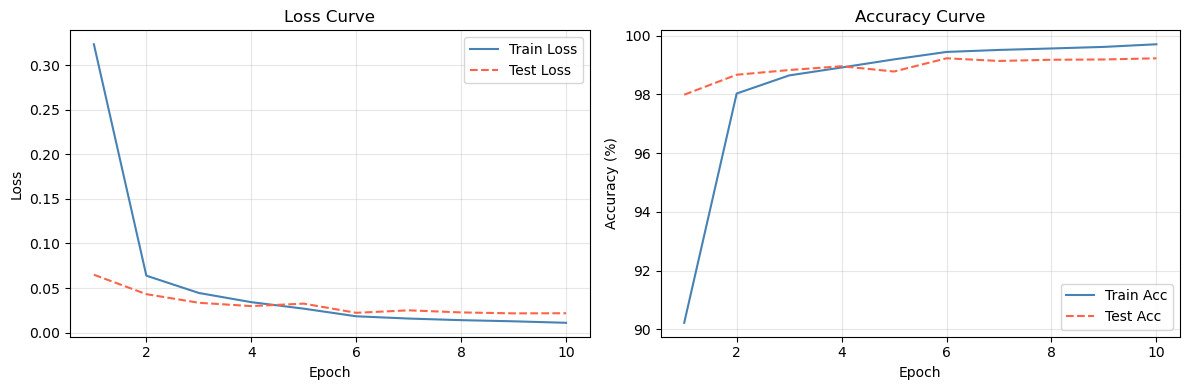

In [8]:
## ── 9. 可视化训练曲线 ───────────────────────────────────
epochs = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, train_losses, label="Train Loss", color="steelblue")
ax1.plot(epochs, test_losses,  label="Test Loss",  color="tomato", linestyle="--")
ax1.set_xlabel("Epoch");  ax1.set_ylabel("Loss")
ax1.set_title("Loss Curve");  ax1.legend();  ax1.grid(alpha=0.3)

ax2.plot(epochs, [a*100 for a in train_accs], label="Train Acc", color="steelblue")
ax2.plot(epochs, [a*100 for a in test_accs],  label="Test Acc",  color="tomato", linestyle="--")
ax2.set_xlabel("Epoch");  ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy Curve");  ax2.legend();  ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

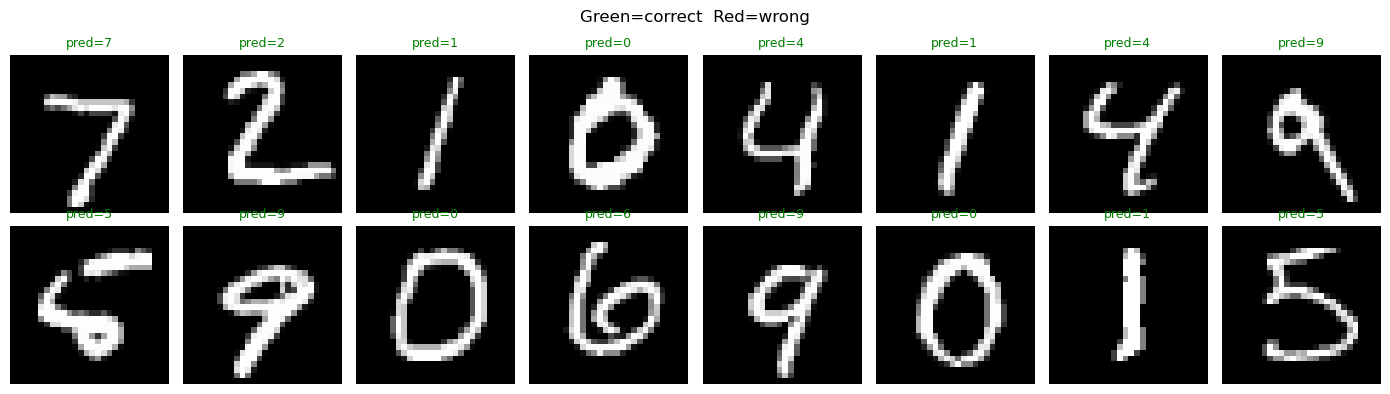

In [9]:
## ── 10. 可视化预测结果 ──────────────────────────────────
model.eval()
images, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    color = "green" if preds[i] == labels[i] else "red"
    ax.set_title(f"pred={preds[i].item()}", color=color, fontsize=9)
    ax.axis("off")

plt.suptitle("Green=correct  Red=wrong")
plt.tight_layout()
plt.show()